theoretical PMF
P(X=0) 0.7
p(x=1) 0.3

 Generated observations
[0 0 0 0 1 0 1 0 1 0 1 1 0 1 0 0 0 0 1 0]

 Number of observations generated: 20
Number of clicks 7
Number of non clicks 13
Do counts add upto 20? True

 empirical PMF
P(X=0)= 0.65
P(X=1)= 0.35

 comparisons
Theoretical P(X=1): 0.3
Empirical P(X=1): 0.35
Theoretical P(X=1): 0.7
Empirical P(X=0): 0.65


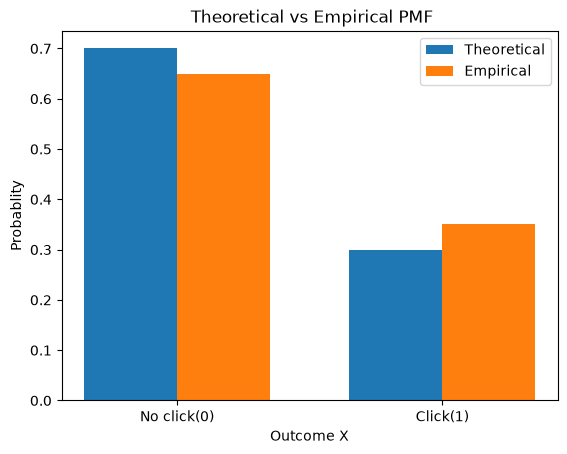

 Theoretical expectation 0.3
empirical expectation 0.35
Theoretical Variance = 0.21
Empirical Variance = 0.22749999999999998

Final Result Table
-----------------------------------------------------------------
Measure                  Theoretical    Empirical      Absolute Difference
-----------------------------------------------------------------
P(X=1) Click             0.3000         0.3500         0.0500
P(X=0) Non-click         0.7000         0.6500         0.0500
Expectation              0.3000         0.3500         0.0500
Variance                 0.2100         0.2275         0.0175

Effect of Sample Size
-----------------------------------------------------------------
Sample Size    Empirical P(Click)  Empirical Mean      Empirical Variance
-----------------------------------------------------------------
10             0.2000              0.2000              0.1600
100            0.2500              0.2500              0.1875
1000           0.3030              0.3030      

In [2]:
import numpy as np
import matplotlib.pyplot as plt

#define random variable
p = 0.30
 
#define number of customers
sample_size = 20

#Theoretical probablity mean function

x = np.array([0,1])

#theoretical probablities

theoretical_pmf = np.array([ 1-p , p])  #1-p,P(X=0) and #p,P(X=1)

print("theoretical PMF")
print("P(X=0)", theoretical_pmf[0])
print("p(x=1)",theoretical_pmf[1])


# generate outcomes for 20 customers
# Bernoulli observations using Binomial(n=1)

samples = np.random.binomial( n=1, p=p, size=sample_size)

print("\n Generated observations")
print(samples)

print("\n Number of observations generated:", len(samples))

# count clicks and non clicks

# 1 = click
number_of_clicks = np.sum(samples == 1)

# 0 = non-click
number_of_non_clicks = np.sum(samples == 0)

print("Number of clicks", number_of_clicks)
print("Number of non clicks", number_of_non_clicks)

print("Do counts add upto 20?", number_of_non_clicks + number_of_clicks == 20)

#calculate empirical PMF

empirical_pmf = np.array([number_of_non_clicks/sample_size,
                          number_of_clicks/sample_size])

print("\n empirical PMF")
print("P(X=0)=", empirical_pmf[0])
print("P(X=1)=",empirical_pmf[1])

# compare empirical and theoretical pmfs

print("\n comparisons")
print("Theoretical P(X=1):", p)
print("Empirical P(X=1):",empirical_pmf[1])

print("Theoretical P(X=1):",1-p)
print("Empirical P(X=0):", empirical_pmf[0])


#7 plot empirical and theoretical PMFs

width = 0.35

plt.bar(x - width/2, theoretical_pmf, width, label="Theoretical")

plt.bar(x + width/2 , empirical_pmf, width, label="Empirical")

plt.xlabel("Outcome X")
plt.ylabel("Probablity")
plt.title(" Theoretical vs Empirical PMF")
plt.xticks([0,1],["No click(0)","Click(1)"])
plt.legend()
plt.show()


#theoretical expectation

theoretical_mean = p
print(" Theoretical expectation", theoretical_mean)

#empirical expectation

empirical_mean = np.mean(samples)
print("empirical expectation", empirical_mean)

#theoretical variance
theoretical_variance = p * (1 - p)

print("Theoretical Variance =", theoretical_variance)


# --------------------------------------------------
# Step 11: Empirical variance
# --------------------------------------------------

empirical_variance = np.var(samples)

print("Empirical Variance =", empirical_variance)


# --------------------------------------------------
# Step 12: Final result table
# --------------------------------------------------

theoretical_values = [
    p,
    1 - p,
    theoretical_mean,
    theoretical_variance
]

empirical_values = [
    empirical_pmf[1],
    empirical_pmf[0],
    empirical_mean,
    empirical_variance
]

measures = [
    "P(X=1) Click",
    "P(X=0) Non-click",
    "Expectation",
    "Variance"
]

print("\nFinal Result Table")
print("-" * 65)
print(f"{'Measure':<25}{'Theoretical':<15}{'Empirical':<15}{'Absolute Difference'}")
print("-" * 65)

for measure, theoretical, empirical in zip(
    measures,
    theoretical_values,
    empirical_values
):
    difference = abs(theoretical - empirical)

    print(
        f"{measure:<25}"
        f"{theoretical:<15.4f}"
        f"{empirical:<15.4f}"
        f"{difference:.4f}"
    )


# --------------------------------------------------
# Step 13: Effect of sample size
# --------------------------------------------------

sample_sizes = [10, 100, 1000, 10000]

print("\nEffect of Sample Size")
print("-" * 65)
print(
    f"{'Sample Size':<15}"
    f"{'Empirical P(Click)':<20}"
    f"{'Empirical Mean':<20}"
    f"{'Empirical Variance'}"
)
print("-" * 65)

for n in sample_sizes:

    samples_n = np.random.binomial(
        n=1,
        p=p,
        size=n
    )

    empirical_probability = np.mean(samples_n)
    empirical_mean_n = np.mean(samples_n)
    empirical_variance_n = np.var(samples_n)

    print(
        f"{n:<15}"
        f"{empirical_probability:<20.4f}"
        f"{empirical_mean_n:<20.4f}"
        f"{empirical_variance_n:.4f}"
    )

Number of simulated hours: 20000

First 20 simulated hours:
[1 3 4 2 4 1 2 1 3 1 4 2 1 2 3 5 1 1 1 3]

Average number of flagged transactions per hour: 2.00565
Minimum flagged transactions in an hour: 0
Maximum flagged transactions in an hour: 10

Hours with more than 4 flagged transactions: 997
Hours with 4 or fewer flagged transactions: 19003

Empirical probability of more than 4 flagged: 0.04985
Empirical probability of 4 or fewer flagged: 0.95015


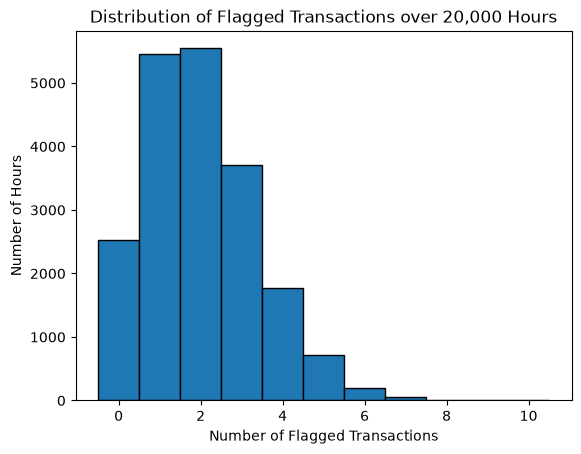

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# Problem Set 2
# --------------------------------------------------

# Number of transactions examined every hour
n_transactions = 50

# Probability that a transaction is flagged
p_flag = 0.04

# Number of simulated hours
num_hours = 20000


# --------------------------------------------------
# Simulate 20,000 independent hours
# --------------------------------------------------

flagged_transactions = np.random.binomial(
    n=n_transactions,
    p=p_flag,
    size=num_hours
)


# --------------------------------------------------
# Display basic results
# --------------------------------------------------

print("Number of simulated hours:", num_hours)

print("\nFirst 20 simulated hours:")
print(flagged_transactions[:20])


# --------------------------------------------------
# Average number of flagged transactions
# --------------------------------------------------

average_flagged = np.mean(flagged_transactions)

print("\nAverage number of flagged transactions per hour:",
      average_flagged)


# --------------------------------------------------
# Maximum and minimum
# --------------------------------------------------

print("Minimum flagged transactions in an hour:",
      np.min(flagged_transactions))

print("Maximum flagged transactions in an hour:",
      np.max(flagged_transactions))


# --------------------------------------------------
# Number of hours with more than 4 flagged
# --------------------------------------------------

hours_more_than_4 = np.sum(flagged_transactions > 4)

print("\nHours with more than 4 flagged transactions:",
      hours_more_than_4)


# --------------------------------------------------
# Number of hours with 4 or fewer flagged
# --------------------------------------------------

hours_at_most_4 = np.sum(flagged_transactions <= 4)

print("Hours with 4 or fewer flagged transactions:",
      hours_at_most_4)


# --------------------------------------------------
# Probability that more than 4 are flagged
# --------------------------------------------------

prob_more_than_4 = hours_more_than_4 / num_hours

print("\nEmpirical probability of more than 4 flagged:",
      prob_more_than_4)


# --------------------------------------------------
# Probability that team can examine all flagged
# --------------------------------------------------

prob_at_most_4 = hours_at_most_4 / num_hours

print("Empirical probability of 4 or fewer flagged:",
      prob_at_most_4)


# --------------------------------------------------
# Plot the simulation
# --------------------------------------------------

plt.hist(
    flagged_transactions,
    bins=np.arange(
        flagged_transactions.min(),
        flagged_transactions.max() + 2
    ) - 0.5,
    edgecolor="black"
)

plt.xlabel("Number of Flagged Transactions")
plt.ylabel("Number of Hours")
plt.title("Distribution of Flagged Transactions over 20,000 Hours")
plt.show()